In [1]:
#Import packages used
import matplotlib
import matplotlib.pyplot as plt
import numpy as np

#Load custom module
from os.path import dirname, abspath
d = dirname(abspath(""))
import sys
sys.path.append(d + '\\EOsimSuite')
from EOsimsuite import EOsimsuite as EOsim

In [2]:
#Sensitivity function - rs are resource concs
def sensFunc(rs,specInd,EOparams):
    K = EOparams['K']
    Y = EOparams['Y']
    nu = EOparams['nu']
    
    sens = nu[specInd] * np.prod(np.array([rs[rho]/(rs[rho] + K[specInd,rho]) if Y[specInd,rho] < 0 else 1 for rho in range(len(rs))]))

    return sens

#Impact function for a single species
def impactFunc(rs,specInd,EOparams):
    K = EOparams['K']
    Y = EOparams['Y']
    nu = EOparams['nu']

    sens = nu[specInd] * np.prod(np.array([rs[rho]/(rs[rho] + K[specInd,rho]) if Y[specInd,rho] < 0 else 1 for rho in range(len(rs))]))
    
    impact = np.array([sens * Y[specInd,rho] for rho in range(len(rs))])

    return impact

In [5]:
#Parameters for the model
dX = 0.5
Dn = 5 #Diffusion constant of metabolites (toxin + nutrient) (um^2/s)
Db = 0.5 #Diffusion constant of bacteria (um^2/s)

nu = np.array([1,1]) #Maximal growth rates
rIn = np.array([10,10,0.01]) #Concs. in plate (pro, try and glu)
K = np.array([[1,1,1],[1,1,1]]) #Half-saturation consts. Index 1 is the species, index 2 is the resource
Y = np.array([[0.5,-1,-1],[-1,0.5,-1]])

B0 = np.array([1,1])/2

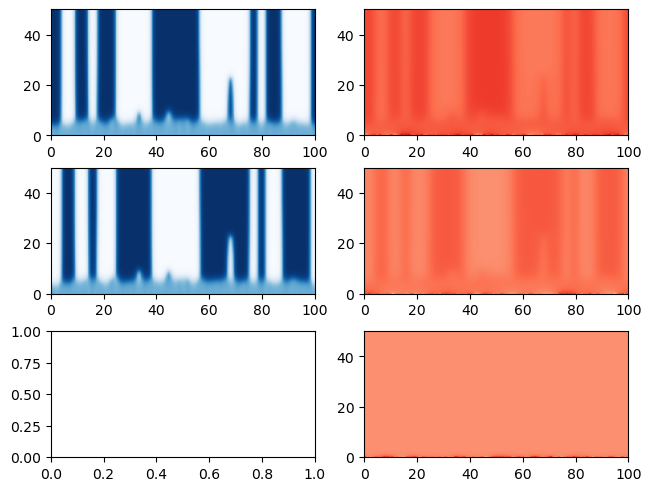

In [9]:
#specNoise is the initial noisiness of species in the inoculation region (increase for a more patchy start), resourceNoise is the same for the environmental compounds
sysParams = {'rIn':rIn,'specNoise':0.01,'resNoise':0.01,'specDiffConst':0.2,'resDiffConst':2,'dX':dX}
EOparams = {'K':K,'nu':nu,'Y':Y}

thisSim = EOsim(impactFunc,sensFunc,EOparams,sysParams,B0,rIn)
thisSim.set_spaceSettings(L = 100, dX=dX) #L is the length of the simulated domain, dX is the pixel size
thisSim.set_timeSettings(tSpan = [0,50], dt=0.1)
thisSim.set_dilSettings(D=0.5,transT=0.1) #D is the dilution rate for each volume element (how quickly the contents is replaced by the media in the plate)
thisSim.set_initConds(B0,rIn,True)
thisSim.simEOmodel('Colony')
thisSim.plotSolutionTimecourse()